# 01 — Dataset Understanding

## Objective

This notebook performs an initial investigation of the xView2
disaster damage assessment dataset.

The objectives are:

- Understand the dataset directory structure.
- Identify available image and annotation files.
- Verify pre-disaster and post-disaster image pairs.
- Inspect annotation formats and damage categories.
- Analyze dataset distribution.
- Identify missing, corrupted, or inconsistent files.

The findings from this notebook will guide subsequent
exploratory data analysis and preprocessing.

In [2]:
# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path
from collections import Counter
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# ============================================================
# 2. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path.cwd()

# Handle execution from the notebooks directory
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_ROOT = PROJECT_ROOT / "dataset"

# Available datasets
DATASET_SPLITS = ["train", "hold", "test", "tier3"]

print("Project Root:", PROJECT_ROOT)
print("Dataset Root:", DATASET_ROOT)

# Verify dataset directory
assert PROJECT_ROOT.exists(), "Project directory does not exist!"
assert DATASET_ROOT.exists(), "Dataset directory does not exist!"

print("\nProject setup completed successfully.")

Project Root: d:\ML_Project
Dataset Root: d:\ML_Project\dataset

Project setup completed successfully.


## 2. Dataset Directory Structure

Inspect the downloaded datasets and identify the available
subdirectories, including images, labels, and targets.

This helps us understand how the dataset is organized
before analyzing its contents.

In [3]:
# ============================================================
# DATASET DIRECTORY INSPECTION
# ============================================================

for split in DATASET_SPLITS:

    split_path = DATASET_ROOT / split

    print("\n" + "=" * 60)
    print(f"DATASET: {split.upper()}")
    print("=" * 60)

    if not split_path.exists():
        print("Dataset directory not found!")
        continue

    for folder in sorted(split_path.iterdir()):

        if folder.is_dir():

            file_count = sum(
                1 for file in folder.rglob("*")
                if file.is_file()
            )

            print(f"{folder.name:<15} : {file_count:>10,} files")

        elif folder.is_file():

            print(f"{folder.name:<15} : File")


DATASET: TRAIN
images          :      5,598 files
labels          :      5,598 files
targets         :      5,598 files

DATASET: HOLD
images          :      1,866 files
labels          :      1,866 files
targets         :      1,866 files

DATASET: TEST
images          :      1,866 files
labels          :      1,866 files
targets         :      1,866 files

DATASET: TIER3
images          :     12,738 files
labels          :     12,738 files


In [4]:
# ============================================================
# FILE EXTENSION ANALYSIS
# ============================================================

for split in DATASET_SPLITS:

    split_path = DATASET_ROOT / split

    if not split_path.exists():
        continue

    print("\n" + "=" * 60)
    print(f"{split.upper()} FILE EXTENSIONS")
    print("=" * 60)

    for folder_name in ["images", "labels", "targets"]:

        folder_path = split_path / folder_name

        if not folder_path.exists():
            print(f"\n{folder_name}: Directory not found")
            continue

        extensions = Counter(
            file.suffix.lower()
            for file in folder_path.rglob("*")
            if file.is_file()
        )

        print(f"\n{folder_name.upper()}:")

        for extension, count in sorted(extensions.items()):
            print(f"{extension or '[no extension]':<15}: {count:,}")


TRAIN FILE EXTENSIONS

IMAGES:
.png           : 5,598

LABELS:
.json          : 5,598

TARGETS:
.png           : 5,598

HOLD FILE EXTENSIONS

IMAGES:
.png           : 1,866

LABELS:
.json          : 1,866

TARGETS:
.png           : 1,866

TEST FILE EXTENSIONS

IMAGES:
.png           : 1,866

LABELS:
.json          : 1,866

TARGETS:
.png           : 1,866

TIER3 FILE EXTENSIONS

IMAGES:
.png           : 12,738

LABELS:
.json          : 12,738

targets: Directory not found


## 3. Image and Annotation File Matching

In this section, we verify the correspondence between:

- Pre-disaster images
- Post-disaster images
- JSON annotations
- Target segmentation masks

We also identify missing files and unmatched image pairs.

The verification is performed independently for each dataset split.

In [5]:
# ============================================================
# SAMPLE FILENAME INSPECTION
# ============================================================

for split in DATASET_SPLITS:

    images_dir = DATASET_ROOT / split / "images"
    labels_dir = DATASET_ROOT / split / "labels"

    if not images_dir.exists():
        continue

    print("\n" + "=" * 60)
    print(f"{split.upper()} SAMPLE FILES")
    print("=" * 60)

    print("\nImages:")

    for file in sorted(images_dir.iterdir())[:6]:
        print(file.name)

    print("\nLabels:")

    for file in sorted(labels_dir.iterdir())[:6]:
        print(file.name)

    targets_dir = DATASET_ROOT / split / "targets"

    if targets_dir.exists():
        print("\nTargets:")

        for file in sorted(targets_dir.iterdir())[:6]:
            print(file.name)


TRAIN SAMPLE FILES

Images:
guatemala-volcano_00000000_post_disaster.png
guatemala-volcano_00000000_pre_disaster.png
guatemala-volcano_00000001_post_disaster.png
guatemala-volcano_00000001_pre_disaster.png
guatemala-volcano_00000002_post_disaster.png
guatemala-volcano_00000002_pre_disaster.png

Labels:
guatemala-volcano_00000000_post_disaster.json
guatemala-volcano_00000000_pre_disaster.json
guatemala-volcano_00000001_post_disaster.json
guatemala-volcano_00000001_pre_disaster.json
guatemala-volcano_00000002_post_disaster.json
guatemala-volcano_00000002_pre_disaster.json

Targets:
guatemala-volcano_00000000_post_disaster_target.png
guatemala-volcano_00000000_pre_disaster_target.png
guatemala-volcano_00000001_post_disaster_target.png
guatemala-volcano_00000001_pre_disaster_target.png
guatemala-volcano_00000002_post_disaster_target.png
guatemala-volcano_00000002_pre_disaster_target.png

HOLD SAMPLE FILES

Images:
guatemala-volcano_00000004_post_disaster.png
guatemala-volcano_00000004_pre

In [6]:
# ============================================================
# IMAGE PAIR VERIFICATION
# ============================================================

import re

def get_image_pairs(images_dir):

    pre_images = {}
    post_images = {}

    for file in images_dir.glob("*.png"):

        stem = file.stem

        match = re.search(
            r"_(pre|post)_disaster$",
            stem,
            re.IGNORECASE
        )

        if not match:
            continue

        disaster_id = stem[:match.start()]
        image_type = match.group(1).lower()

        if image_type == "pre":
            pre_images[disaster_id] = file

        elif image_type == "post":
            post_images[disaster_id] = file

    return pre_images, post_images


pair_results = {}

for split in DATASET_SPLITS:

    images_dir = DATASET_ROOT / split / "images"

    if not images_dir.exists():
        continue

    pre_images, post_images = get_image_pairs(images_dir)

    pre_ids = set(pre_images)
    post_ids = set(post_images)

    matched_ids = pre_ids & post_ids

    missing_post = pre_ids - post_ids
    missing_pre = post_ids - pre_ids

    pair_results[split] = {
        "pre": len(pre_images),
        "post": len(post_images),
        "matched": len(matched_ids),
        "missing_post": len(missing_post),
        "missing_pre": len(missing_pre),
    }

    print("\n" + "=" * 60)
    print(f"{split.upper()} IMAGE PAIR ANALYSIS")
    print("=" * 60)

    print("Pre-disaster images :", len(pre_images))
    print("Post-disaster images:", len(post_images))
    print("Matched pairs       :", len(matched_ids))
    print("Missing post images :", len(missing_post))
    print("Missing pre images  :", len(missing_pre))

    if missing_post:
        print("Example missing post:", list(missing_post)[:5])

    if missing_pre:
        print("Example missing pre :", list(missing_pre)[:5])


TRAIN IMAGE PAIR ANALYSIS
Pre-disaster images : 2799
Post-disaster images: 2799
Matched pairs       : 2799
Missing post images : 0
Missing pre images  : 0

HOLD IMAGE PAIR ANALYSIS
Pre-disaster images : 933
Post-disaster images: 933
Matched pairs       : 933
Missing post images : 0
Missing pre images  : 0

TEST IMAGE PAIR ANALYSIS
Pre-disaster images : 933
Post-disaster images: 933
Matched pairs       : 933
Missing post images : 0
Missing pre images  : 0

TIER3 IMAGE PAIR ANALYSIS
Pre-disaster images : 6369
Post-disaster images: 6369
Matched pairs       : 6369
Missing post images : 0
Missing pre images  : 0


In [7]:
# ============================================================
# FILE CORRESPONDENCE VERIFICATION
# ============================================================

for split in DATASET_SPLITS:

    split_dir = DATASET_ROOT / split

    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"
    targets_dir = split_dir / "targets"

    if not images_dir.exists():
        continue

    image_stems = {
        file.stem for file in images_dir.glob("*.png")
    }

    label_stems = {
        file.stem for file in labels_dir.glob("*.json")
    }

    print("\n" + "=" * 60)
    print(f"{split.upper()} FILE MATCHING")
    print("=" * 60)

    print("Images :", len(image_stems))
    print("Labels :", len(label_stems))

    print("Images without labels:",
          len(image_stems - label_stems))

    print("Labels without images:",
          len(label_stems - image_stems))

    if targets_dir.exists():

        target_stems = {
            file.stem for file in targets_dir.glob("*.png")
        }

        print("Targets:", len(target_stems))

        print("Images without targets:",
              len(image_stems - target_stems))

        print("Targets without images:",
              len(target_stems - image_stems))

    else:
        print("Targets: Not available")


TRAIN FILE MATCHING
Images : 5598
Labels : 5598
Images without labels: 0
Labels without images: 0
Targets: 5598
Images without targets: 5598
Targets without images: 5598

HOLD FILE MATCHING
Images : 1866
Labels : 1866
Images without labels: 0
Labels without images: 0
Targets: 1866
Images without targets: 1866
Targets without images: 1866

TEST FILE MATCHING
Images : 1866
Labels : 1866
Images without labels: 0
Labels without images: 0
Targets: 1866
Images without targets: 1866
Targets without images: 1866

TIER3 FILE MATCHING
Images : 12738
Labels : 12738
Images without labels: 0
Labels without images: 0
Targets: Not available


In [8]:
# ============================================================
# FILE CORRESPONDENCE VERIFICATION
# ============================================================

for split in DATASET_SPLITS:

    split_dir = DATASET_ROOT / split

    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"
    targets_dir = split_dir / "targets"

    if not images_dir.exists():
        continue

    # Collect image filenames
    image_stems = {
        file.stem
        for file in images_dir.glob("*.png")
    }

    # Collect annotation filenames
    label_stems = {
        file.stem
        for file in labels_dir.glob("*.json")
    }

    print("\n" + "=" * 60)
    print(f"{split.upper()} FILE MATCHING")
    print("=" * 60)

    print("Images :", len(image_stems))
    print("Labels :", len(label_stems))

    print("Images without labels:",
          len(image_stems - label_stems))

    print("Labels without images:",
          len(label_stems - image_stems))

    # Verify target masks
    if targets_dir.exists():

        target_stems = {
            file.stem.removesuffix("_target")
            for file in targets_dir.glob("*.png")
        }

        print("Targets:", len(target_stems))

        print("Images without targets:",
              len(image_stems - target_stems))

        print("Targets without images:",
              len(target_stems - image_stems))

    else:
        print("Targets: Not available (expected to be investigated)")


TRAIN FILE MATCHING
Images : 5598
Labels : 5598
Images without labels: 0
Labels without images: 0
Targets: 5598
Images without targets: 0
Targets without images: 0

HOLD FILE MATCHING
Images : 1866
Labels : 1866
Images without labels: 0
Labels without images: 0
Targets: 1866
Images without targets: 0
Targets without images: 0

TEST FILE MATCHING
Images : 1866
Labels : 1866
Images without labels: 0
Labels without images: 0
Targets: 1866
Images without targets: 0
Targets without images: 0

TIER3 FILE MATCHING
Images : 12738
Labels : 12738
Images without labels: 0
Labels without images: 0
Targets: Not available (expected to be investigated)


## 4. JSON Annotation Inspection

The xView2 annotations are stored in GeoJSON format.

Each annotation file contains building-level information,
including polygon geometry and building properties.

We will inspect one pre-disaster and one post-disaster
annotation to understand their structure.

In [9]:
# ============================================================
# LOAD SAMPLE PRE AND POST ANNOTATIONS
# ============================================================

split = "train"

images_dir = DATASET_ROOT / split / "images"
labels_dir = DATASET_ROOT / split / "labels"

pre_images, post_images = get_image_pairs(images_dir)

matched_ids = sorted(set(pre_images) & set(post_images))

sample_id = matched_ids[0]

pre_json_path = labels_dir / f"{sample_id}_pre_disaster.json"
post_json_path = labels_dir / f"{sample_id}_post_disaster.json"

with open(pre_json_path, "r") as file:
    pre_data = json.load(file)

with open(post_json_path, "r") as file:
    post_data = json.load(file)

print("Sample ID:", sample_id)

print("\nPre-disaster JSON:")
print("Top-level keys:", list(pre_data.keys()))

print("\nPost-disaster JSON:")
print("Top-level keys:", list(post_data.keys()))

print("\nPre-disaster metadata:")
print(json.dumps(pre_data.get("metadata", {}), indent=4))

print("\nPost-disaster metadata:")
print(json.dumps(post_data.get("metadata", {}), indent=4))

Sample ID: guatemala-volcano_00000000

Pre-disaster JSON:
Top-level keys: ['features', 'metadata']

Post-disaster JSON:
Top-level keys: ['features', 'metadata']

Pre-disaster metadata:
{
    "sensor": "WORLDVIEW03_VNIR",
    "provider_asset_type": "WORLDVIEW03_VNIR",
    "gsd": 1.3459189,
    "capture_date": "2018-02-05T17:10:18.000Z",
    "off_nadir_angle": 17.933279,
    "pan_resolution": 0.3362646,
    "sun_azimuth": 150.80763000000002,
    "sun_elevation": 55.506645,
    "target_azimuth": 118.24727,
    "disaster": "guatemala-volcano",
    "disaster_type": "volcano",
    "catalog_id": "10400100377A9B00",
    "original_width": 1024,
    "original_height": 1024,
    "width": 1024,
    "height": 1024,
    "id": "MjUxMzEyMA.FwIEh3iVRb5-R_EXW9amgViNSoA",
    "img_name": "guatemala-volcano_00000000_pre_disaster.png"
}

Post-disaster metadata:
{
    "sensor": "WORLDVIEW03_VNIR",
    "provider_asset_type": "WORLDVIEW03_VNIR",
    "gsd": 1.4085245,
    "capture_date": "2018-06-22T16:55:40.0

In [14]:
# ============================================================
# DEBUG: INSPECT FEATURES STRUCTURE
# ============================================================

print("Pre-disaster features type:", type(pre_data["features"]))

print("\nPre-disaster feature keys:")
print(list(pre_data["features"].keys())
      if isinstance(pre_data["features"], dict)
      else "Features is a list")

print("\nPre-disaster features preview:")
print(json.dumps(pre_data["features"], indent=4)[:2000])


print("\nPost-disaster features type:", type(post_data["features"]))

print("\nPost-disaster features preview:")
print(json.dumps(post_data["features"], indent=4)[:2000])


Pre-disaster features type: <class 'dict'>

Pre-disaster feature keys:
['lng_lat', 'xy']

Pre-disaster features preview:
{
    "lng_lat": [
        {
            "properties": {
                "feature_type": "building",
                "uid": "486b0813-ecd2-4b84-856c-9c0e42156953"
            },
            "wkt": "POLYGON ((-90.8154467949004 14.39086318334907, -90.81590706308027 14.39071123556949, -90.81587964154231 14.39059650626618, -90.81595559688809 14.3905736709202, -90.8159334443047 14.39048145754321, -90.81586635209149 14.39049581582651, -90.81584174451078 14.39043032648, -90.81537467349251 14.39060467857228, -90.8154467949004 14.39086318334907))"
        },
        {
            "properties": {
                "feature_type": "building",
                "uid": "139cf2c8-ad52-4739-82b5-bb646b215e76"
            },
            "wkt": "POLYGON ((-90.81420592026568 14.38829423654955, -90.81421178335277 14.38832937106096, -90.81408837763034 14.38834314934303, -90.81404547542751 1

In [16]:
# ============================================================
# BUILDING FEATURE INSPECTION
# ============================================================

def inspect_annotation(data, label):

    features = data.get("features", {})

    print("\n" + "=" * 60)
    print(label.upper())
    print("=" * 60)

    print("Feature structure:", type(features))
    print("Available coordinate systems:", list(features.keys()))

    for coordinate_system in ["lng_lat", "xy"]:

        records = features.get(coordinate_system, [])

        print("\n" + "-" * 50)
        print(f"COORDINATE SYSTEM: {coordinate_system}")
        print("-" * 50)

        print("Total building features:", len(records))

        if not records:
            continue

        feature = records[0]

        print("\nFeature keys:")
        print(list(feature.keys()))

        print("\nBuilding properties:")
        print(json.dumps(feature.get("properties", {}), indent=4))

        print("\nGeometry (WKT):")
        print(feature.get("wkt", "Not available")[:500])


inspect_annotation(pre_data, "Pre-disaster")
inspect_annotation(post_data, "Post-disaster")


PRE-DISASTER
Feature structure: <class 'dict'>
Available coordinate systems: ['lng_lat', 'xy']

--------------------------------------------------
COORDINATE SYSTEM: lng_lat
--------------------------------------------------
Total building features: 10

Feature keys:
['properties', 'wkt']

Building properties:
{
    "feature_type": "building",
    "uid": "486b0813-ecd2-4b84-856c-9c0e42156953"
}

Geometry (WKT):
POLYGON ((-90.8154467949004 14.39086318334907, -90.81590706308027 14.39071123556949, -90.81587964154231 14.39059650626618, -90.81595559688809 14.3905736709202, -90.8159334443047 14.39048145754321, -90.81586635209149 14.39049581582651, -90.81584174451078 14.39043032648, -90.81537467349251 14.39060467857228, -90.8154467949004 14.39086318334907))

--------------------------------------------------
COORDINATE SYSTEM: xy
--------------------------------------------------
Total building features: 10

Feature keys:
['properties', 'wkt']

Building properties:
{
    "feature_type": "bui

In [17]:
# ============================================================
# PRE AND POST BUILDING UID COMPARISON
# ============================================================

def extract_buildings(data):

    buildings = data["features"]["xy"]

    return {
        feature["properties"]["uid"]: feature["properties"]
        for feature in buildings
    }


pre_buildings = extract_buildings(pre_data)
post_buildings = extract_buildings(post_data)

pre_uids = set(pre_buildings.keys())
post_uids = set(post_buildings.keys())

common_uids = pre_uids & post_uids

print("Pre-disaster buildings :", len(pre_uids))
print("Post-disaster buildings:", len(post_uids))
print("Common building UIDs   :", len(common_uids))
print("Missing post UIDs      :", len(pre_uids - post_uids))
print("Missing pre UIDs       :", len(post_uids - pre_uids))

print("\nSample common building UIDs:")
for uid in list(sorted(common_uids))[:5]:
    print(uid)

Pre-disaster buildings : 10
Post-disaster buildings: 10
Common building UIDs   : 10
Missing post UIDs      : 0
Missing pre UIDs       : 0

Sample common building UIDs:
139cf2c8-ad52-4739-82b5-bb646b215e76
486b0813-ecd2-4b84-856c-9c0e42156953
563b145d-732d-4eb4-8c77-380519842324
56f51b26-d511-461d-bb31-747901a4ea75
7fd91a32-cf6c-43f2-b059-8c77c92a5693


## 5. Damage Class Distribution Analysis

This section analyzes building-level damage annotations
across the complete training dataset.

The objectives are:

- Count buildings belonging to each damage category.
- Identify missing or unclassified damage labels.
- Calculate the percentage distribution of each category.
- Understand the class imbalance problem.

In [18]:
# ============================================================
# DAMAGE CLASS DISTRIBUTION - TRAINING DATASET
# ============================================================

from collections import Counter

train_labels_dir = DATASET_ROOT / "train" / "labels"

damage_counts = Counter()

total_buildings = 0
missing_subtype = 0
total_tiles = 0

for json_file in sorted(train_labels_dir.glob("*_post_disaster.json")):

    with open(json_file, "r") as file:
        data = json.load(file)

    features = data.get("features", {})

    buildings = features.get("xy", [])

    total_tiles += 1

    for building in buildings:

        properties = building.get("properties", {})

        subtype = properties.get("subtype")

        if subtype is None:
            subtype = "missing"
            missing_subtype += 1

        damage_counts[subtype] += 1
        total_buildings += 1


print("=" * 60)
print("TRAINING DATASET DAMAGE DISTRIBUTION")
print("=" * 60)

print("Total post-disaster annotation files:", total_tiles)
print("Total building annotations:", total_buildings)
print("Missing subtype annotations:", missing_subtype)

print("\nDamage category counts:")

for category, count in sorted(damage_counts.items()):

    percentage = (count / total_buildings) * 100

    print(
        f"{category:<20} "
        f"{count:>10,} "
        f"{percentage:>8.2f}%"
    )

TRAINING DATASET DAMAGE DISTRIBUTION
Total post-disaster annotation files: 2799
Total building annotations: 162787
Missing subtype annotations: 0

Damage category counts:
destroyed                13,227     8.13%
major-damage             14,161     8.70%
minor-damage             14,980     9.20%
no-damage               117,426    72.13%
un-classified             2,993     1.84%


In [19]:
# ============================================================
# DAMAGE CLASS DISTRIBUTION - TRAINING DATASET
# ============================================================

from collections import Counter

train_labels_dir = DATASET_ROOT / "train" / "labels"

damage_counts = Counter()

total_buildings = 0
missing_subtype = 0
total_tiles = 0

for json_file in sorted(train_labels_dir.glob("*_post_disaster.json")):

    with open(json_file, "r") as file:
        data = json.load(file)

    features = data.get("features", {})

    buildings = features.get("xy", [])

    total_tiles += 1

    for building in buildings:

        properties = building.get("properties", {})

        subtype = properties.get("subtype")

        if subtype is None:
            subtype = "missing"
            missing_subtype += 1

        damage_counts[subtype] += 1
        total_buildings += 1


print("=" * 60)
print("TRAINING DATASET DAMAGE DISTRIBUTION")
print("=" * 60)

print("Total post-disaster annotation files:", total_tiles)
print("Total building annotations:", total_buildings)
print("Missing subtype annotations:", missing_subtype)

print("\nDamage category counts:")

for category, count in sorted(damage_counts.items()):

    percentage = (count / total_buildings) * 100

    print(
        f"{category:<20} "
        f"{count:>10,} "
        f"{percentage:>8.2f}%"
    )

TRAINING DATASET DAMAGE DISTRIBUTION
Total post-disaster annotation files: 2799
Total building annotations: 162787
Missing subtype annotations: 0

Damage category counts:
destroyed                13,227     8.13%
major-damage             14,161     8.70%
minor-damage             14,980     9.20%
no-damage               117,426    72.13%
un-classified             2,993     1.84%


In [20]:
# ============================================================
# CLASS IMBALANCE ANALYSIS
# ============================================================

valid_counts = {
    category: count
    for category, count in damage_counts.items()
    if category != "missing"
}

if valid_counts:

    majority_class = max(valid_counts, key=valid_counts.get)
    minority_class = min(valid_counts, key=valid_counts.get)

    imbalance_ratio = (
        valid_counts[majority_class] /
        valid_counts[minority_class]
    )

    print("Majority class:", majority_class)
    print("Minority class:", minority_class)

    print("Majority count:", valid_counts[majority_class])
    print("Minority count:", valid_counts[minority_class])

    print(f"Class imbalance ratio: {imbalance_ratio:.2f}:1")

Majority class: no-damage
Minority class: un-classified
Majority count: 117426
Minority count: 2993
Class imbalance ratio: 39.23:1


## 6. Image Properties and Target Mask Analysis

This section investigates the physical properties of satellite
images and their corresponding segmentation target masks.

We examine:

- Image dimensions
- Image color modes
- Image data types
- Target mask dimensions
- Unique target mask pixel values
- Pixel frequency distribution

The purpose is to understand the target encoding before
implementing the segmentation preprocessing pipeline.

In [21]:
# ============================================================
# IMAGE PROPERTY INSPECTION
# ============================================================

sample_image_paths = [
    DATASET_ROOT / "train" / "images" /
    "guatemala-volcano_00000000_pre_disaster.png",

    DATASET_ROOT / "train" / "images" /
    "guatemala-volcano_00000000_post_disaster.png"
]

for image_path in sample_image_paths:

    with Image.open(image_path) as img:

        image_array = np.array(img)

        print("\n" + "=" * 60)
        print(image_path.name)
        print("=" * 60)

        print("Dimensions:", img.size)
        print("Width:", img.width)
        print("Height:", img.height)
        print("Color mode:", img.mode)
        print("Array shape:", image_array.shape)
        print("Data type:", image_array.dtype)
        print("Minimum pixel value:", image_array.min())
        print("Maximum pixel value:", image_array.max())


guatemala-volcano_00000000_pre_disaster.png
Dimensions: (1024, 1024)
Width: 1024
Height: 1024
Color mode: RGB
Array shape: (1024, 1024, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255

guatemala-volcano_00000000_post_disaster.png
Dimensions: (1024, 1024)
Width: 1024
Height: 1024
Color mode: RGB
Array shape: (1024, 1024, 3)
Data type: uint8
Minimum pixel value: 4
Maximum pixel value: 255


In [22]:
# ============================================================
# TARGET MASK INSPECTION
# ============================================================

sample_masks = [
    DATASET_ROOT / "train" / "targets" /
    "guatemala-volcano_00000000_pre_disaster_target.png",

    DATASET_ROOT / "train" / "targets" /
    "guatemala-volcano_00000000_post_disaster_target.png"
]

for mask_path in sample_masks:

    with Image.open(mask_path) as mask:

        mask_array = np.array(mask)

        print("\n" + "=" * 60)
        print(mask_path.name)
        print("=" * 60)

        print("Dimensions:", mask.size)
        print("Color mode:", mask.mode)
        print("Array shape:", mask_array.shape)
        print("Data type:", mask_array.dtype)

        unique_values, counts = np.unique(
            mask_array,
            return_counts=True
        )

        print("\nUnique pixel values:")

        for value, count in zip(unique_values, counts):

            percentage = count / mask_array.size * 100

            print(
                f"Value {value:>3}: "
                f"{count:>10,} pixels "
                f"({percentage:.2f}%)"
            )


guatemala-volcano_00000000_pre_disaster_target.png
Dimensions: (1024, 1024)
Color mode: L
Array shape: (1024, 1024)
Data type: uint8

Unique pixel values:
Value   0:  1,032,725 pixels (98.49%)
Value   1:     15,851 pixels (1.51%)

guatemala-volcano_00000000_post_disaster_target.png
Dimensions: (1024, 1024)
Color mode: L
Array shape: (1024, 1024)
Data type: uint8

Unique pixel values:
Value   0:  1,032,738 pixels (98.49%)
Value   1:     15,838 pixels (1.51%)


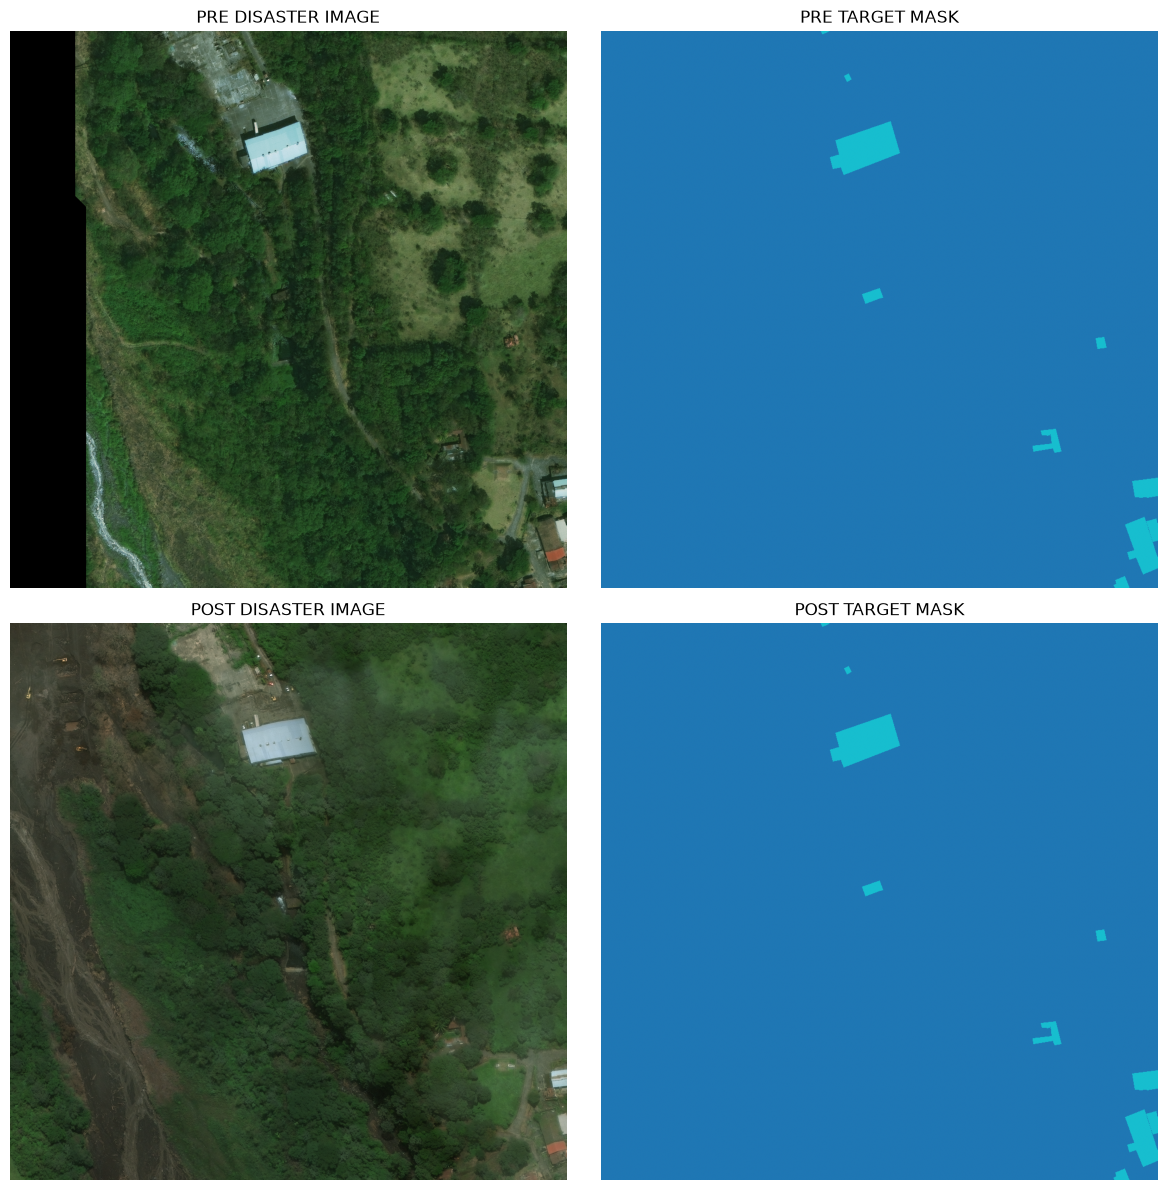

In [23]:
# ============================================================
# IMAGE AND TARGET MASK VISUALIZATION
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for row, image_type in enumerate(["pre", "post"]):

    image_path = (
        DATASET_ROOT / "train" / "images" /
        f"guatemala-volcano_00000000_{image_type}_disaster.png"
    )

    mask_path = (
        DATASET_ROOT / "train" / "targets" /
        f"guatemala-volcano_00000000_{image_type}_disaster_target.png"
    )

    image = np.array(Image.open(image_path))
    mask = np.array(Image.open(mask_path))

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{image_type.upper()} DISASTER IMAGE")

    axes[row, 1].imshow(mask, cmap="tab10")
    axes[row, 1].set_title(f"{image_type.upper()} TARGET MASK")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# TRAINING IMAGE DIMENSION VALIDATION
# ============================================================

dimension_counts = Counter()
mode_counts = Counter()

train_images_dir = DATASET_ROOT / "train" / "images"

for image_path in train_images_dir.glob("*.png"):

    with Image.open(image_path) as img:

        dimension_counts[img.size] += 1
        mode_counts[img.mode] += 1

print("IMAGE DIMENSION DISTRIBUTION")
print("=" * 45)

for dimensions, count in dimension_counts.items():
    print(f"{dimensions}: {count:,}")

print("\nIMAGE COLOR MODE DISTRIBUTION")
print("=" * 45)

for mode, count in mode_counts.items():
    print(f"{mode}: {count:,}")

IMAGE DIMENSION DISTRIBUTION
(1024, 1024): 5,598

IMAGE COLOR MODE DISTRIBUTION
RGB: 5,598


## 7. Dataset-wide Target Mask Validation

This section verifies target-mask consistency across the
entire training dataset.

We investigate:

- Unique pixel values across all masks.
- Mask dimensions and data types.
- Foreground and background pixel distributions.
- Differences between pre-disaster and post-disaster masks.

In [25]:
# ============================================================
# DATASET-WIDE TARGET MASK ANALYSIS
# ============================================================

from collections import Counter

targets_dir = DATASET_ROOT / "train" / "targets"

global_pixel_counts = Counter()
mask_dimensions = Counter()
mask_dtypes = Counter()
mask_modes = Counter()

mask_count = 0

for mask_path in sorted(targets_dir.glob("*.png")):

    with Image.open(mask_path) as mask:

        mask_array = np.array(mask)

        mask_count += 1

        mask_dimensions[mask.size] += 1
        mask_modes[mask.mode] += 1
        mask_dtypes[str(mask_array.dtype)] += 1

        values, counts = np.unique(
            mask_array,
            return_counts=True
        )

        global_pixel_counts.update(
            dict(zip(values.tolist(), counts.tolist()))
        )

print("TOTAL MASKS:", mask_count)

print("\nMASK DIMENSIONS:")
print(mask_dimensions)

print("\nMASK COLOR MODES:")
print(mask_modes)

print("\nMASK DATA TYPES:")
print(mask_dtypes)

print("\nGLOBAL PIXEL DISTRIBUTION:")

total_pixels = sum(global_pixel_counts.values())

for value, count in sorted(global_pixel_counts.items()):

    percentage = count / total_pixels * 100

    print(
        f"Pixel {value}: "
        f"{count:,} pixels "
        f"({percentage:.4f}%)"
    )

print("\nTotal pixels:", f"{total_pixels:,}")

TOTAL MASKS: 5598

MASK DIMENSIONS:
Counter({(1024, 1024): 5598})

MASK COLOR MODES:
Counter({'L': 5598})

MASK DATA TYPES:
Counter({'uint8': 5598})

GLOBAL PIXEL DISTRIBUTION:
Pixel 0: 5,520,674,380 pixels (94.0501%)
Pixel 1: 303,689,524 pixels (5.1736%)
Pixel 2: 15,935,603 pixels (0.2715%)
Pixel 3: 20,121,556 pixels (0.3428%)
Pixel 4: 9,507,385 pixels (0.1620%)

Total pixels: 5,869,928,448


In [26]:
# ============================================================
# PRE VS POST MASK COVERAGE
# ============================================================

coverage = {
    "pre": [],
    "post": []
}

for mask_path in sorted(targets_dir.glob("*.png")):

    if "_pre_disaster_target" in mask_path.name:
        image_type = "pre"

    elif "_post_disaster_target" in mask_path.name:
        image_type = "post"

    else:
        continue

    mask = np.array(Image.open(mask_path))

    foreground_pixels = np.count_nonzero(mask == 1)

    coverage[image_type].append(
        foreground_pixels / mask.size * 100
    )


for image_type, values in coverage.items():

    print("\n", image_type.upper(), "DISASTER MASKS")
    print("Number of masks:", len(values))
    print(f"Mean building coverage: {np.mean(values):.4f}%")
    print(f"Median coverage: {np.median(values):.4f}%")
    print(f"Minimum coverage: {np.min(values):.4f}%")
    print(f"Maximum coverage: {np.max(values):.4f}%")


 PRE DISASTER MASKS
Number of masks: 2799
Mean building coverage: 5.9781%
Median coverage: 1.2916%
Minimum coverage: 0.0000%
Maximum coverage: 67.1550%

 POST DISASTER MASKS
Number of masks: 2799
Mean building coverage: 4.3692%
Median coverage: 0.3652%
Minimum coverage: 0.0000%
Maximum coverage: 67.0323%


## 8. Pre-Disaster vs Post-Disaster Mask Encoding

Analyze pre-disaster and post-disaster target masks separately.

The purpose is to identify whether:

- Pre-disaster masks contain binary building footprints.
- Post-disaster masks contain damage severity classes.
- Pixel values are consistent across the dataset.

In [27]:
# ============================================================
# PRE VS POST TARGET MASK PIXEL DISTRIBUTION
# ============================================================

mask_pixel_counts = {
    "pre": Counter(),
    "post": Counter()
}

mask_totals = {
    "pre": 0,
    "post": 0
}

for mask_path in sorted(targets_dir.glob("*.png")):

    if "_pre_disaster_target" in mask_path.name:
        image_type = "pre"

    elif "_post_disaster_target" in mask_path.name:
        image_type = "post"

    else:
        continue

    mask = np.array(Image.open(mask_path))

    values, counts = np.unique(
        mask,
        return_counts=True
    )

    mask_pixel_counts[image_type].update(
        dict(zip(values.tolist(), counts.tolist()))
    )

    mask_totals[image_type] += mask.size


for image_type in ["pre", "post"]:

    print("\n" + "=" * 60)
    print(f"{image_type.upper()} DISASTER MASK DISTRIBUTION")
    print("=" * 60)

    for value, count in sorted(
        mask_pixel_counts[image_type].items()
    ):

        percentage = (
            count / mask_totals[image_type] * 100
        )

        print(
            f"Pixel {value}: "
            f"{count:>15,} "
            f"({percentage:>8.4f}%)"
        )

    print("Total pixels:", f"{mask_totals[image_type]:,}")


PRE DISASTER MASK DISTRIBUTION
Pixel 0:   2,759,510,516 ( 94.0219%)
Pixel 1:     175,453,708 (  5.9781%)
Total pixels: 2,934,964,224

POST DISASTER MASK DISTRIBUTION
Pixel 0:   2,761,163,864 ( 94.0783%)
Pixel 1:     128,235,816 (  4.3692%)
Pixel 2:      15,935,603 (  0.5430%)
Pixel 3:      20,121,556 (  0.6856%)
Pixel 4:       9,507,385 (  0.3239%)
Total pixels: 2,934,964,224


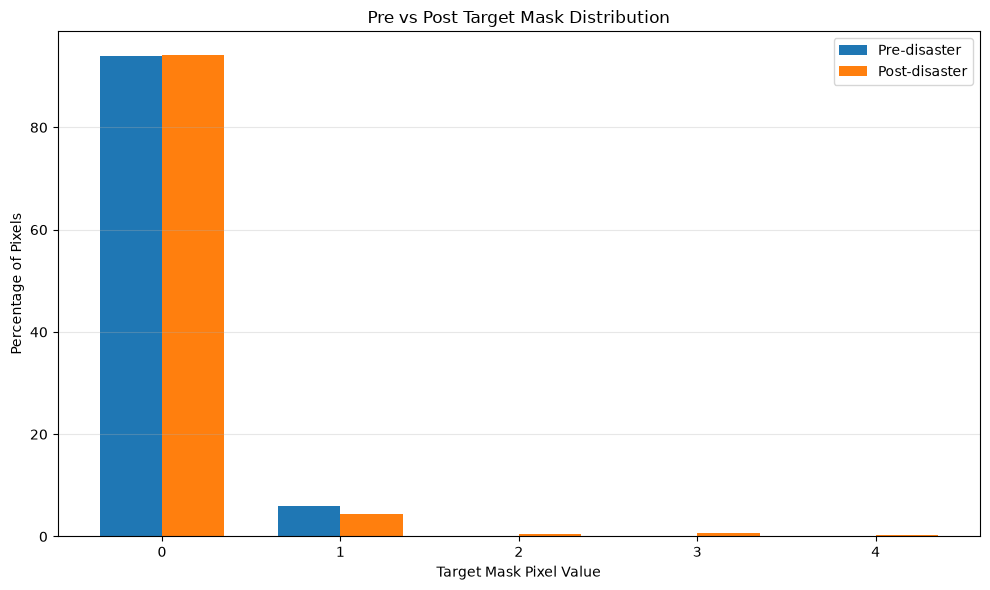

In [28]:
# ============================================================
# PRE VS POST PIXEL DISTRIBUTION
# ============================================================

pixel_values = [0, 1, 2, 3, 4]

pre_percentages = [
    mask_pixel_counts["pre"].get(v, 0)
    / mask_totals["pre"] * 100
    for v in pixel_values
]

post_percentages = [
    mask_pixel_counts["post"].get(v, 0)
    / mask_totals["post"] * 100
    for v in pixel_values
]

x = np.arange(len(pixel_values))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    pre_percentages,
    width,
    label="Pre-disaster"
)

plt.bar(
    x + width / 2,
    post_percentages,
    width,
    label="Post-disaster"
)

plt.xticks(x, pixel_values)

plt.xlabel("Target Mask Pixel Value")
plt.ylabel("Percentage of Pixels")
plt.title("Pre vs Post Target Mask Distribution")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Validation of JSON Damage Labels Against Target Masks

This section verifies the relationship between building-level
damage annotations and pixel-level target masks.

We will:

- Extract post-disaster building polygons.
- Read their damage subtypes.
- Compare polygon regions against target-mask values.
- Investigate unclassified buildings.
- Verify the damage-class encoding.

In [30]:
# ============================================================
# INDIVIDUAL BUILDING LABEL INSPECTION
# ============================================================

from collections import defaultdict

sample_id = "guatemala-volcano_00000000"

post_json_path = (
    DATASET_ROOT / "train" / "labels" /
    f"{sample_id}_post_disaster.json"
)

post_mask_path = (
    DATASET_ROOT / "train" / "targets" /
    f"{sample_id}_post_disaster_target.png"
)

with open(post_json_path, "r") as file:
    annotation = json.load(file)

mask = np.array(Image.open(post_mask_path))

subtype_counts = Counter()

for building in annotation["features"]["xy"]:

    properties = building["properties"]

    subtype = properties.get("subtype", "missing")

    subtype_counts[subtype] += 1

print("JSON DAMAGE SUBTYPE COUNTS")
print("=" * 45)

for subtype, count in subtype_counts.items():
    print(f"{subtype:<20}: {count}")

print("\nTARGET MASK PIXEL VALUES")
print("=" * 45)

values, counts = np.unique(mask, return_counts=True)

for value, count in zip(values, counts):
    print(f"Pixel {value}: {count:,}")

JSON DAMAGE SUBTYPE COUNTS
no-damage           : 10

TARGET MASK PIXEL VALUES
Pixel 0: 1,032,738
Pixel 1: 15,838


In [31]:
# ============================================================
# UNCLASSIFIED BUILDING INSPECTION
# ============================================================

unclassified_buildings = []

for building in annotation["features"]["xy"]:

    properties = building["properties"]

    if properties.get("subtype") == "un-classified":

        unclassified_buildings.append({
            "uid": properties.get("uid"),
            "wkt": building.get("wkt")
        })

print("Unclassified buildings:",
      len(unclassified_buildings))

for building in unclassified_buildings[:5]:

    print("\nUID:", building["uid"])
    print("Polygon:", building["wkt"])

Unclassified buildings: 0


## 10. Finding Representative Damage Annotations

The initial sample contains only no-damage buildings.

We will search the complete training dataset to identify
image tiles containing multiple damage categories.

These tiles will be used to validate the target-mask encoding.

In [32]:
# ============================================================
# FIND REPRESENTATIVE DAMAGE SAMPLES
# ============================================================

train_labels_dir = DATASET_ROOT / "train" / "labels"

damage_categories = [
    "no-damage",
    "minor-damage",
    "major-damage",
    "destroyed",
    "un-classified"
]

representative_samples = []

for json_path in sorted(
    train_labels_dir.glob("*_post_disaster.json")
):

    with open(json_path, "r") as file:
        data = json.load(file)

    buildings = data["features"]["xy"]

    counts = Counter(
        building["properties"].get("subtype", "missing")
        for building in buildings
    )

    present_classes = [
        category for category in damage_categories
        if counts[category] > 0
    ]

    if len(present_classes) >= 3:

        sample_id = json_path.stem.replace(
            "_post_disaster", ""
        )

        representative_samples.append({
            "sample_id": sample_id,
            "classes": present_classes,
            "counts": dict(counts)
        })


print("Representative tiles found:",
      len(representative_samples))

for sample in representative_samples[:10]:

    print("\nSample:", sample["sample_id"])
    print("Classes:", sample["classes"])
    print("Counts:", sample["counts"])

Representative tiles found: 829

Sample: guatemala-volcano_00000019
Classes: ['no-damage', 'minor-damage', 'major-damage', 'destroyed']
Counts: {'major-damage': 3, 'destroyed': 1, 'no-damage': 17, 'minor-damage': 1}

Sample: guatemala-volcano_00000025
Classes: ['major-damage', 'destroyed', 'un-classified']
Counts: {'un-classified': 174, 'destroyed': 21, 'major-damage': 6}

Sample: hurricane-florence_00000001
Classes: ['no-damage', 'minor-damage', 'un-classified']
Counts: {'no-damage': 88, 'minor-damage': 2, 'un-classified': 1}

Sample: hurricane-florence_00000048
Classes: ['no-damage', 'minor-damage', 'major-damage', 'un-classified']
Counts: {'major-damage': 13, 'no-damage': 5, 'minor-damage': 5, 'un-classified': 1}

Sample: hurricane-florence_00000051
Classes: ['no-damage', 'minor-damage', 'major-damage']
Counts: {'minor-damage': 2, 'major-damage': 17, 'no-damage': 1}

Sample: hurricane-florence_00000055
Classes: ['no-damage', 'minor-damage', 'major-damage', 'un-classified']
Counts: {

In [33]:
# ============================================================
# SELECT REPRESENTATIVE SAMPLE
# ============================================================

if representative_samples:

    selected_sample = representative_samples[0]

    sample_id = selected_sample["sample_id"]

    print("Selected sample:", sample_id)
    print("Damage classes:", selected_sample["classes"])
    print("Building counts:", selected_sample["counts"])

else:

    print("No tile containing three or more damage classes found.")

Selected sample: guatemala-volcano_00000019
Damage classes: ['no-damage', 'minor-damage', 'major-damage', 'destroyed']
Building counts: {'major-damage': 3, 'destroyed': 1, 'no-damage': 17, 'minor-damage': 1}


In [34]:
# ============================================================
# INSPECT REPRESENTATIVE TARGET MASK
# ============================================================

post_json_path = (
    DATASET_ROOT / "train" / "labels" /
    f"{sample_id}_post_disaster.json"
)

post_mask_path = (
    DATASET_ROOT / "train" / "targets" /
    f"{sample_id}_post_disaster_target.png"
)

with open(post_json_path, "r") as file:
    annotation = json.load(file)

mask = np.array(Image.open(post_mask_path))

print("Sample:", sample_id)

print("\nJSON damage distribution:")

subtype_counts = Counter(
    building["properties"].get("subtype", "missing")
    for building in annotation["features"]["xy"]
)

for subtype, count in sorted(subtype_counts.items()):
    print(f"{subtype:<20}: {count:,}")

print("\nTarget pixel distribution:")

values, counts = np.unique(mask, return_counts=True)

for value, count in zip(values, counts):

    print(
        f"Pixel {value}: {count:,} "
        f"({count / mask.size * 100:.4f}%)"
    )

Sample: guatemala-volcano_00000019

JSON damage distribution:
destroyed           : 1
major-damage        : 3
minor-damage        : 1
no-damage           : 17

Target pixel distribution:
Pixel 0: 1,016,756 (96.9654%)
Pixel 1: 26,845 (2.5601%)
Pixel 2: 2,146 (0.2047%)
Pixel 3: 776 (0.0740%)
Pixel 4: 2,053 (0.1958%)


## 11. Building Polygon and Target Mask Alignment

This section validates whether the target mask assigns
the expected damage class to each annotated building.

We rasterize individual building polygons using image-space
coordinates and compare their pixels against the target mask.

This helps validate the relationship between:
- Building polygon geometry
- JSON damage subtype
- Target mask pixel encoding

In [35]:
# ============================================================
# POLYGON-TO-MASK VALIDATION
# ============================================================

from PIL import ImageDraw
from shapely import wkt
from collections import defaultdict

EXPECTED_DAMAGE_MAPPING = {
    "no-damage": 1,
    "minor-damage": 2,
    "major-damage": 3,
    "destroyed": 4
}

# Load selected sample
annotation_path = (
    DATASET_ROOT / "train" / "labels" /
    f"{sample_id}_post_disaster.json"
)

mask_path = (
    DATASET_ROOT / "train" / "targets" /
    f"{sample_id}_post_disaster_target.png"
)

with open(annotation_path, "r") as file:
    annotation = json.load(file)

target_mask = np.array(Image.open(mask_path))

# Store results by damage subtype
validation_results = defaultdict(Counter)

for building in annotation["features"]["xy"]:

    properties = building["properties"]

    subtype = properties.get("subtype", "missing")

    if subtype not in EXPECTED_DAMAGE_MAPPING:
        continue

    polygon = wkt.loads(building["wkt"])

    # Create a binary mask for this individual polygon
    polygon_mask = Image.new(
        "L",
        (target_mask.shape[1], target_mask.shape[0]),
        0
    )

    draw = ImageDraw.Draw(polygon_mask)

    # Rasterize polygon in image-coordinate space
    coordinates = [
        (round(x), round(y))
        for x, y in polygon.exterior.coords
    ]

    draw.polygon(coordinates, fill=1)

    polygon_array = np.array(polygon_mask).astype(bool)

    # Extract corresponding target-mask pixels
    pixels = target_mask[polygon_array]

    values, counts = np.unique(
        pixels,
        return_counts=True
    )

    for value, count in zip(values, counts):
        validation_results[subtype][int(value)] += int(count)


print("=" * 65)
print("POLYGON-TO-MASK VALIDATION")
print("=" * 65)

for subtype, pixel_counts in sorted(validation_results.items()):

    expected_value = EXPECTED_DAMAGE_MAPPING[subtype]

    total = sum(pixel_counts.values())

    expected_pixels = pixel_counts.get(expected_value, 0)

    agreement = expected_pixels / total * 100 if total else 0

    print(f"\nDamage category: {subtype}")
    print("Expected pixel value:", expected_value)
    print("Observed pixel counts:", dict(pixel_counts))
    print(f"Expected-class pixel agreement: {agreement:.2f}%")

POLYGON-TO-MASK VALIDATION

Damage category: destroyed
Expected pixel value: 4
Observed pixel counts: {4: 2040}
Expected-class pixel agreement: 100.00%

Damage category: major-damage
Expected pixel value: 3
Observed pixel counts: {3: 744}
Expected-class pixel agreement: 100.00%

Damage category: minor-damage
Expected pixel value: 2
Observed pixel counts: {2: 2114}
Expected-class pixel agreement: 100.00%

Damage category: no-damage
Expected pixel value: 1
Observed pixel counts: {1: 26592}
Expected-class pixel agreement: 100.00%


In [ ]:
# ============================================================
# DAMAGE ENCODING VALIDATION SUMMARY
# ============================================================

print("=" * 60)
print("DAMAGE ENCODING VALIDATION SUMMARY")
print("=" * 60)

for subtype, expected_value in EXPECTED_DAMAGE_MAPPING.items():

    observed = validation_results.get(subtype, Counter())

    total = sum(observed.values())

    expected_count = observed.get(expected_value, 0)

    agreement = (
        expected_count / total * 100
        if total > 0 else 0
    )

    print(
        f"{subtype:<18} "
        f"Expected: {expected_value} "
        f"Agreement: {agreement:.2f}%"
    )


DAMAGE ENCODING VALIDATION SUMMARY
no-damage          Expected: 1 Agreement: 100.00%
minor-damage       Expected: 2 Agreement: 100.00%
major-damage       Expected: 3 Agreement: 100.00%
destroyed          Expected: 4 Agreement: 100.00%


## 12. Disaster Type Distribution

Analyze the disaster events represented in the training dataset.

Objectives:
- Identify unique disaster events.
- Count image pairs per disaster.
- Analyze disaster-type distribution.
- Understand dataset diversity.

In [37]:
# ============================================================
# DISASTER TYPE DISTRIBUTION
# ============================================================

disaster_counts = Counter()
disaster_type_counts = Counter()

train_labels_dir = DATASET_ROOT / "train" / "labels"

for json_path in sorted(
    train_labels_dir.glob("*_post_disaster.json")
):

    with open(json_path, "r") as file:
        data = json.load(file)

    metadata = data.get("metadata", {})

    disaster = metadata.get("disaster", "unknown")
    disaster_type = metadata.get("disaster_type", "unknown")

    disaster_counts[disaster] += 1
    disaster_type_counts[disaster_type] += 1


print("UNIQUE DISASTER EVENTS:", len(disaster_counts))

print("\nDISASTER EVENT DISTRIBUTION")
print("=" * 55)

for disaster, count in sorted(
    disaster_counts.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{disaster:<35}: {count:>5,}")

print("\nDISASTER TYPE DISTRIBUTION")
print("=" * 55)

for disaster_type, count in sorted(
    disaster_type_counts.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{disaster_type:<25}: {count:>5,}")

UNIQUE DISASTER EVENTS: 10

DISASTER EVENT DISTRIBUTION
socal-fire                         :   823
hurricane-michael                  :   343
hurricane-florence                 :   319
hurricane-harvey                   :   319
midwest-flooding                   :   279
hurricane-matthew                  :   238
santa-rosa-wildfire                :   226
mexico-earthquake                  :   121
palu-tsunami                       :   113
guatemala-volcano                  :    18

DISASTER TYPE DISTRIBUTION
fire                     : 1,049
flooding                 :   917
wind                     :   581
earthquake               :   121
tsunami                  :   113
volcano                  :    18


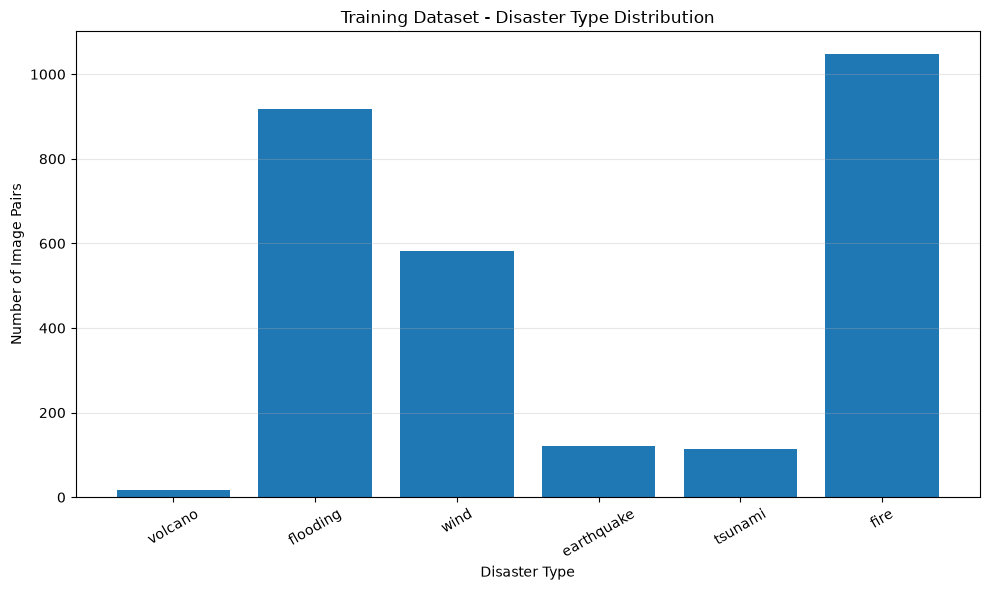

In [38]:
# ============================================================
# DISASTER TYPE VISUALIZATION
# ============================================================

types = list(disaster_type_counts.keys())
counts = list(disaster_type_counts.values())

plt.figure(figsize=(10, 6))

plt.bar(types, counts)

plt.title("Training Dataset - Disaster Type Distribution")
plt.xlabel("Disaster Type")
plt.ylabel("Number of Image Pairs")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 13. Tier3 Dataset Inspection

Investigate the additional Tier3 training dataset.

Objectives:
- Inspect its annotation structure.
- Count building damage categories.
- Compare its metadata with the primary training dataset.
- Determine whether its annotations are compatible
  with the primary dataset.

In [39]:
# ============================================================
# TIER3 JSON STRUCTURE INSPECTION
# ============================================================

tier3_labels_dir = DATASET_ROOT / "tier3" / "labels"

tier3_sample_path = next(
    tier3_labels_dir.glob("*_post_disaster.json")
)

with open(tier3_sample_path, "r") as file:
    tier3_data = json.load(file)

print("Sample file:", tier3_sample_path.name)

print("\nTop-level keys:")
print(list(tier3_data.keys()))

print("\nMetadata:")
print(json.dumps(tier3_data.get("metadata", {}), indent=4))

print("\nFeature coordinate systems:")
print(list(tier3_data.get("features", {}).keys()))

print("\nBuilding feature count:",
      len(tier3_data["features"].get("xy", [])))

if tier3_data["features"].get("xy"):
    print("\nFirst building properties:")
    print(json.dumps(
        tier3_data["features"]["xy"][0]["properties"],
        indent=4
    ))

Sample file: joplin-tornado_00000000_post_disaster.json

Top-level keys:
['features', 'metadata']

Metadata:
{
    "sensor": "WORLDVIEW02",
    "provider_asset_type": "WORLDVIEW02",
    "gsd": 2.35255861282349,
    "capture_date": "2011-05-29T17:29:25.433Z",
    "off_nadir_angle": 28.4302768707275,
    "pan_resolution": 0.585882604122162,
    "sun_azimuth": 143.603851318359,
    "sun_elevation": 71.8531799316406,
    "target_azimuth": 193.251083374023,
    "disaster": "joplin-tornado",
    "disaster_type": "wind",
    "catalog_id": "103001000A285500",
    "original_width": 1024,
    "original_height": 1024,
    "width": 1024,
    "height": 1024,
    "id": "MjY0Mzk4Mg.vo5dFUhTfoVWnKNLRID8rEkx0A0",
    "img_name": "joplin-tornado_00000000_post_disaster.png"
}

Feature coordinate systems:
['lng_lat', 'xy']

Building feature count: 185

First building properties:
{
    "feature_type": "building",
    "subtype": "destroyed",
    "uid": "b6aa615e-56b2-458a-b404-d094b64dcad3"
}


In [40]:
# ============================================================
# TIER3 DAMAGE CLASS DISTRIBUTION
# ============================================================

tier3_damage_counts = Counter()
tier3_total_buildings = 0

tier3_post_files = sorted(
    tier3_labels_dir.glob("*_post_disaster.json")
)

for json_path in tier3_post_files:

    with open(json_path, "r") as file:
        data = json.load(file)

    buildings = data.get("features", {}).get("xy", [])

    for building in buildings:

        subtype = building.get("properties", {}).get(
            "subtype", "missing"
        )

        tier3_damage_counts[subtype] += 1
        tier3_total_buildings += 1


print("TIER3 DAMAGE DISTRIBUTION")
print("=" * 55)

print("Post-disaster annotation files:", len(tier3_post_files))
print("Total buildings:", tier3_total_buildings)

for subtype, count in sorted(tier3_damage_counts.items()):

    percentage = count / tier3_total_buildings * 100

    print(
        f"{subtype:<20}: "
        f"{count:>10,} "
        f"({percentage:.2f}%)"
    )

TIER3 DAMAGE DISTRIBUTION
Post-disaster annotation files: 6369
Total buildings: 153327
destroyed           :     10,335 (6.74%)
major-damage        :      7,288 (4.75%)
minor-damage        :     10,744 (7.01%)
no-damage           :    116,209 (75.79%)
un-classified       :      8,751 (5.71%)


## 14. Tier3 Geometry and Annotation Validation

Tier3 does not contain pre-generated target masks.

This section validates whether its building polygons can
be used to generate segmentation masks.

We inspect:
- Pre/post building UID correspondence.
- Polygon geometry validity.
- Polygon coordinate bounds.
- Annotation compatibility with image dimensions.

In [41]:
# ============================================================
# TIER3 PRE/POST UID VALIDATION
# ============================================================

tier3_images_dir = DATASET_ROOT / "tier3" / "images"
tier3_labels_dir = DATASET_ROOT / "tier3" / "labels"

tier3_pre_images, tier3_post_images = get_image_pairs(
    tier3_images_dir
)

tier3_common_ids = sorted(
    set(tier3_pre_images) & set(tier3_post_images)
)

total_pairs = 0
total_common_uids = 0
total_missing_uids = 0

for sample_id in tier3_common_ids:

    pre_path = (
        tier3_labels_dir /
        f"{sample_id}_pre_disaster.json"
    )

    post_path = (
        tier3_labels_dir /
        f"{sample_id}_post_disaster.json"
    )

    with open(pre_path) as f:
        pre = json.load(f)

    with open(post_path) as f:
        post = json.load(f)

    pre_uids = {
        b["properties"]["uid"]
        for b in pre["features"]["xy"]
    }

    post_uids = {
        b["properties"]["uid"]
        for b in post["features"]["xy"]
    }

    total_pairs += 1
    total_common_uids += len(pre_uids & post_uids)
    total_missing_uids += len(pre_uids ^ post_uids)


print("Tier3 image pairs:", total_pairs)
print("Common building UIDs:", total_common_uids)
print("Non-matching building UIDs:", total_missing_uids)

Tier3 image pairs: 6369
Common building UIDs: 153327
Non-matching building UIDs: 0


In [42]:
# ============================================================
# TIER3 POLYGON GEOMETRY VALIDATION
# ============================================================

from shapely import wkt

geometry_counts = Counter()
invalid_geometries = 0
out_of_bounds = 0
total_polygons = 0

for json_path in tier3_labels_dir.glob("*_post_disaster.json"):

    with open(json_path) as f:
        data = json.load(f)

    for building in data["features"]["xy"]:

        polygon = wkt.loads(building["wkt"])

        total_polygons += 1

        geometry_counts[polygon.geom_type] += 1

        if not polygon.is_valid:
            invalid_geometries += 1

        min_x, min_y, max_x, max_y = polygon.bounds

        if (
            min_x < 0 or min_y < 0 or
            max_x > 1024 or max_y > 1024
        ):
            out_of_bounds += 1


print("Total polygons:", total_polygons)
print("Geometry types:", geometry_counts)
print("Invalid geometries:", invalid_geometries)
print("Out-of-bounds polygons:", out_of_bounds)

Total polygons: 153327
Geometry types: Counter({'Polygon': 153327})
Invalid geometries: 0
Out-of-bounds polygons: 1420


## 15. Investigation of Out-of-Bounds Tier3 Polygons

Some Tier3 building polygons extend beyond the expected
1024 × 1024 image boundaries.

This section investigates the extent of these violations.

We will:
- Count affected polygons.
- Measure how far coordinates extend outside the image.
- Identify severely out-of-bounds polygons.
- Inspect representative examples.

No annotations will be modified.

In [44]:
# ============================================================
# OUT-OF-BOUNDS POLYGON ANALYSIS
# ============================================================

out_of_bounds_records = []

for json_path in sorted(
    tier3_labels_dir.glob("*_post_disaster.json")
):

    with open(json_path) as f:
        data = json.load(f)

    for building in data["features"]["xy"]:

        polygon = wkt.loads(building["wkt"])

        min_x, min_y, max_x, max_y = polygon.bounds

        if (
            min_x < 0 or min_y < 0 or
            max_x > 1024 or max_y > 1024
        ):

            out_of_bounds_records.append({
                "sample": json_path.stem.replace(
                    "_post_disaster", ""
                ),
                "uid": building["properties"]["uid"],
                "subtype": building["properties"].get("subtype"),
                "min_x": min_x,
                "min_y": min_y,
                "max_x": max_x,
                "max_y": max_y,
                "outside_left": max(0, -min_x),
                "outside_top": max(0, -min_y),
                "outside_right": max(0, max_x - 1024),
                "outside_bottom": max(0, max_y - 1024)
            })


out_of_bounds_df = pd.DataFrame(out_of_bounds_records)

print("Affected polygons:", len(out_of_bounds_df))

print("\nMaximum boundary violations:")

for column in [
    "outside_left",
    "outside_top",
    "outside_right",
    "outside_bottom"
]:
    print(
        f"{column}: "
        f"{out_of_bounds_df[column].max():.3f} pixels"
    )

print("\nFirst 10 affected polygons:")

display(out_of_bounds_df.head(10))

Affected polygons: 1420

Maximum boundary violations:
outside_left: 0.167 pixels
outside_top: 0.000 pixels
outside_right: 1.000 pixels
outside_bottom: 0.000 pixels

First 10 affected polygons:


,sample,uid,subtype,min_x,min_y,max_x,max_y,outside_left,outside_top,outside_right,outside_bottom
0,joplin-tornado_00000000,595792d7-b804-4575-8489-3d2f84b6cf7c,destroyed,-2.489378e-07,177.712845,37.771180,224.913521,2.489378e-07,0.0,0.0,0
1,joplin-tornado_00000000,d6ba73da-30f9-4c83-abe3-8b8d6d7b4b14,destroyed,-2.484219e-07,323.201390,32.770566,362.339207,2.484219e-07,0.0,0.0,0
2,joplin-tornado_00000000,36daaddc-2beb-4b86-a953-e293ddd65b6d,destroyed,-2.491958e-07,369.477190,24.446421,421.817172,2.491958e-07,0.0,0.0,0
3,joplin-tornado_00000000,0b9fcbdf-37a5-4678-8e7e-9256c1d83e5b,destroyed,-2.486799e-07,425.343370,23.090538,475.739122,2.486799e-07,0.0,0.0,0
4,joplin-tornado_00000000,56df4bd1-1516-4fa1-a77d-e7fd6135f4ef,destroyed,-2.484219e-07,483.952030,21.311240,532.296781,2.484219e-07,0.0,0.0,0
5,joplin-tornado_00000000,8f6a3a38-84a9-470b-b1f3-70fc78d546af,destroyed,-2.484219e-07,538.892410,19.986880,591.826196,2.484219e-07,0.0,0.0,0
6,joplin-tornado_00000000,d4bea936-c385-44d3-a357-18cccdbd7c24,destroyed,-2.455843e-07,594.459628,16.824424,647.002378,2.455843e-07,0.0,0.0,0
7,joplin-tornado_00000000,b69438ce-e401-4609-891b-a312b29f9e0b,destroyed,-2.484219e-07,651.151235,10.628175,703.639736,2.484219e-07,0.0,0.0,0
8,joplin-tornado_00000000,3e9c9b07-e551-4e5b-8b12-756983b42d75,destroyed,-2.481639e-07,706.528017,9.231542,760.002745,2.481639e-07,0.0,0.0,0
9,joplin-tornado_00000000,e7033975-d4cb-4e53-8bfc-3a5cf02b981c,destroyed,-2.471321e-07,763.494569,6.460520,813.649600,2.471321e-07,0.0,0.0,0


In [ ]:
# ============================================================
# CLASSIFY OUT-OF-BOUNDS POLYGONS
# ============================================================

violation_columns = [
    "outside_left",
    "outside_top",
    "outside_right",
    "outside_bottom"
]

out_of_bounds_df["max_violation"] = (
    out_of_bounds_df[violation_columns].max(axis=1)
)

def classify_violation(value):

    if value <= 1:
        return "Minor (<= 1 pixel)"

    elif value <= 10:
        return "Moderate (1-10 pixels)"

    else:
        return "Severe (> 10 pixels)"


out_of_bounds_df["violation_category"] = (
    out_of_bounds_df["max_violation"].apply(
        classify_violation
    )
)

print("BOUNDARY VIOLATION DISTRIBUTION")
print("=" * 50)

print(
    out_of_bounds_df["violation_category"]
    .value_counts()
)

print("\nMaximum violation:",
      out_of_bounds_df["max_violation"].max())

BOUNDARY VIOLATION DISTRIBUTION
violation_category
Minor (<= 1 pixel)    1420
Name: count, dtype: int64

Maximum violation: 1.0


## 16. Disaster Event Overlap Across Dataset Splits

Investigate whether disaster events are shared between
the training, holdout, and test datasets.

Objectives:
- Identify disaster events in each split.
- Detect overlapping events.
- Calculate event-level overlap.
- Understand the generalization capability measured
  by the current dataset partition.

In [4]:
# ============================================================
# DISASTER EVENT OVERLAP ANALYSIS
# ============================================================

split_disasters = {}

for split in ["train", "hold", "test"]:

    labels_dir = DATASET_ROOT / split / "labels"

    disasters = set()
    disaster_counts = Counter()

    for json_path in labels_dir.glob("*_post_disaster.json"):

        with open(json_path) as f:
            data = json.load(f)

        disaster = data["metadata"].get("disaster", "unknown")

        disasters.add(disaster)
        disaster_counts[disaster] += 1

    split_disasters[split] = disasters

    print("\n" + "=" * 55)
    print(f"{split.upper()} DISASTER EVENTS")
    print("=" * 55)

    print("Unique events:", len(disasters))

    for disaster, count in sorted(disaster_counts.items()):
        print(f"{disaster:<30}: {count:>5}")


TRAIN DISASTER EVENTS
Unique events: 10
guatemala-volcano             :    18
hurricane-florence            :   319
hurricane-harvey              :   319
hurricane-matthew             :   238
hurricane-michael             :   343
mexico-earthquake             :   121
midwest-flooding              :   279
palu-tsunami                  :   113
santa-rosa-wildfire           :   226
socal-fire                    :   823

HOLD DISASTER EVENTS
Unique events: 10
guatemala-volcano             :     5
hurricane-florence            :   119
hurricane-harvey              :    95
hurricane-matthew             :    94
hurricane-michael             :   109
mexico-earthquake             :    34
midwest-flooding              :    86
palu-tsunami                  :    41
santa-rosa-wildfire           :    77
socal-fire                    :   273

TEST DISASTER EVENTS
Unique events: 10
guatemala-volcano             :     5
hurricane-florence            :   108
hurricane-harvey              :   108
hurri

In [5]:
# ============================================================
# DISASTER EVENT OVERLAP
# ============================================================

train_events = split_disasters["train"]
hold_events = split_disasters["hold"]
test_events = split_disasters["test"]

train_hold = train_events & hold_events
train_test = train_events & test_events
hold_test = hold_events & test_events

all_events = (
    train_events | hold_events | test_events
)

print("=" * 60)
print("DISASTER EVENT OVERLAP ANALYSIS")
print("=" * 60)

print("Train events:", len(train_events))
print("Hold events :", len(hold_events))
print("Test events :", len(test_events))

print("\nTrain ∩ Hold:", sorted(train_hold))
print("\nTrain ∩ Test:", sorted(train_test))
print("\nHold ∩ Test:", sorted(hold_test))

print("\nEvents exclusive to train:",
      sorted(train_events - hold_events - test_events))

print("\nEvents exclusive to hold:",
      sorted(hold_events - train_events - test_events))

print("\nEvents exclusive to test:",
      sorted(test_events - train_events - hold_events))

print("\nTotal unique events:", len(all_events))

DISASTER EVENT OVERLAP ANALYSIS
Train events: 10
Hold events : 10
Test events : 10

Train ∩ Hold: ['guatemala-volcano', 'hurricane-florence', 'hurricane-harvey', 'hurricane-matthew', 'hurricane-michael', 'mexico-earthquake', 'midwest-flooding', 'palu-tsunami', 'santa-rosa-wildfire', 'socal-fire']

Train ∩ Test: ['guatemala-volcano', 'hurricane-florence', 'hurricane-harvey', 'hurricane-matthew', 'hurricane-michael', 'mexico-earthquake', 'midwest-flooding', 'palu-tsunami', 'santa-rosa-wildfire', 'socal-fire']

Hold ∩ Test: ['guatemala-volcano', 'hurricane-florence', 'hurricane-harvey', 'hurricane-matthew', 'hurricane-michael', 'mexico-earthquake', 'midwest-flooding', 'palu-tsunami', 'santa-rosa-wildfire', 'socal-fire']

Events exclusive to train: []

Events exclusive to hold: []

Events exclusive to test: []

Total unique events: 10


In [6]:
# ============================================================
# DISASTER EVENT SPLIT MATRIX
# ============================================================

event_matrix = pd.DataFrame(
    index=sorted(all_events),
    columns=["train", "hold", "test"]
)

for event in event_matrix.index:

    for split in ["train", "hold", "test"]:

        event_matrix.loc[event, split] = (
            event in split_disasters[split]
        )

event_matrix = event_matrix.astype(bool)

display(event_matrix)

,train,hold,test
guatemala-volcano,True,True,True
hurricane-florence,True,True,True
hurricane-harvey,True,True,True
hurricane-matthew,True,True,True
hurricane-michael,True,True,True
mexico-earthquake,True,True,True
midwest-flooding,True,True,True
palu-tsunami,True,True,True
santa-rosa-wildfire,True,True,True
socal-fire,True,True,True


In [8]:
# ============================================================
# IMAGE TILE OVERLAP VALIDATION
# ============================================================

import re

split_tile_ids = {}

for split in ["train", "hold", "test"]:

    images_dir = DATASET_ROOT / split / "images"

    tile_ids = set()

    for image_path in images_dir.glob("*.png"):

        match = re.search(
            r"_(pre|post)_disaster$",
            image_path.stem
        )

        if match:
            tile_id = image_path.stem[:match.start()]
            tile_ids.add(tile_id)

    split_tile_ids[split] = tile_ids

    print(
        f"{split.upper()} unique image pairs:",
        len(tile_ids)
    )


# Calculate overlaps
train_hold_overlap = (
    split_tile_ids["train"] & split_tile_ids["hold"]
)

train_test_overlap = (
    split_tile_ids["train"] & split_tile_ids["test"]
)

hold_test_overlap = (
    split_tile_ids["hold"] & split_tile_ids["test"]
)

print("\n" + "=" * 60)
print("IMAGE TILE OVERLAP")
print("=" * 60)

print("Train ∩ Hold:", len(train_hold_overlap))
print("Train ∩ Test:", len(train_test_overlap))
print("Hold ∩ Test:", len(hold_test_overlap))

all_tiles = set.union(*split_tile_ids.values())

print("\nTotal unique image pairs:", len(all_tiles))

assert not train_hold_overlap
assert not train_test_overlap
assert not hold_test_overlap

print("\nNo duplicate image-tile IDs across splits.")

TRAIN unique image pairs: 2799
HOLD unique image pairs: 933
TEST unique image pairs: 933

IMAGE TILE OVERLAP
Train ∩ Hold: 0
Train ∩ Test: 0
Hold ∩ Test: 0

Total unique image pairs: 4665

No duplicate image-tile IDs across splits.



# Dataset Audit — Conclusions

## 1. Dataset Structure
- Train: 2,799 image pairs
- Hold: 933 image pairs
- Test: 933 image pairs
- Tier3: 6,369 image pairs
- Primary dataset (train + hold + test): 4,665 image pairs
- All splits have complete pre/post images and matching JSON annotations.
- Tier3 has annotations but no target masks.

## 2. Image and Annotation Properties
- Images are 1024 × 1024 RGB PNG files.
- Images use uint8 pixel values.
- Annotations contain `lng_lat` and `xy` polygon geometries.
- Building annotations contain unique IDs and damage subtype information.
- Tier3 annotations have a compatible structure with the primary dataset.

## 3. Target Mask Semantics
- Pre-disaster masks: binary building-footprint masks.
  - 0: Background
  - 1: Building
- Post-disaster masks: five pixel values.
  - 0: Background
  - 1: No damage
  - 2: Minor damage
  - 3: Major damage
  - 4: Destroyed

The polygon-to-mask correspondence was verified on a representative sample tile, not yet across the entire dataset.

## 4. Damage Class Distribution
The primary training annotations contain 162,787 post-disaster building annotations.

- No damage: 72.13%
- Minor damage: 9.20%
- Major damage: 8.70%
- Destroyed: 8.13%
- Unclassified: 1.84%

The dataset is imbalanced, with no-damage buildings forming the majority class.

## 5. Split Integrity
- Train: 2,799 unique image pairs
- Hold: 933 unique image pairs
- Test: 933 unique image pairs
- No duplicate tile IDs across the three splits.
- All three splits contain examples from the same 10 disaster events.

The official split prevents tile-level overlap, but does not evaluate generalization to unseen disaster events.

## 6. Important Considerations
- Investigate the treatment of unclassified buildings before model training.
- Account for class imbalance during training and evaluation.
- Preserve Tier3 separately until its suitability for the intended task is fully validated.
- Validate polygon-to-mask alignment on additional samples.
- Consider a separate event-held-out experiment to measure unseen-disaster generalization.

## Conclusion
The dataset structure, annotation schema, target-mask encoding, class distribution, and official split integrity have been inspected.

The dataset is sufficiently understood to proceed to exploratory data analysis. Model architecture and training decisions should be made after examining image characteristics, damage patterns, class imbalance, and annotation quality in greater depth.
